# Evict or quantize? Analysis of the full run

This notebook reads the summary files from the full run in `results/` and works out the headline comparisons.

**Run:** Qwen2.5-1.5B-Instruct (float32 compute, eager attention) on a Kaggle T4, RULER at 4,096 tokens, 25 questions per task, 3 tasks, 6 conditions (450 answers in all). Quantisation uses the KIVI-style cache defined in `kv_eviction_vs_quant.py`; eviction uses kvpress's `ObservedAttentionPress` (H2O-style, scored once before the question).

`full_fp16` is the uncompressed cache. KV sizes are reported for a 16-bit cache, plus 0.5 bit per value for the quantisers' scales and offsets.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

R = "results"
summary = pd.read_csv(f"{R}/summary.csv").set_index("condition")
pairs = pd.read_csv(f"{R}/equal_memory_pairs.csv")
jpc_task = pd.read_csv(f"{R}/energy_per_correct.csv").set_index("condition")
TASKS = ["niah_single_1", "qa_1", "vt"]
summary

,niah_single_1,qa_1,vt,kv_ctx_mb,latency_s,energy_j,peak_mem_gb,n,j_per_correct
condition,,,,,,,,,
full_fp16,100.0,84.0,98.4,95.01,4.29,284.86,8.01,75,302.61
h2o_50,20.0,72.0,13.6,47.50,4.53,298.86,7.91,75,849.03
h2o_75,12.0,72.0,3.2,23.75,4.49,296.75,7.86,75,1020.91
kv_int4,100.0,84.0,96.8,26.71,4.52,297.74,7.86,75,318.10
kv_int2,72.0,76.0,80.0,14.83,4.62,304.94,7.86,75,401.24
h2o_50+kv_int4,20.0,72.0,18.4,13.35,4.59,302.89,7.83,75,823.07


## 1. Accuracy against cost

Mean accuracy over the three tasks, and each condition's cache size, latency and energy relative to the uncompressed cache.

In [2]:
full = summary.loc["full_fp16"]
t = pd.DataFrame({
    "mean accuracy": summary[TASKS].mean(axis=1).round(1),
    "KV cache (MB)": summary["kv_ctx_mb"].round(1),
    "KV smaller by": (full["kv_ctx_mb"] / summary["kv_ctx_mb"]).round(2).astype(str) + "x",
    "energy / answer vs full": ((summary["energy_j"] / full["energy_j"] - 1) * 100).round(1).astype(str) + "%",
    "latency vs full": ((summary["latency_s"] / full["latency_s"] - 1) * 100).round(1).astype(str) + "%",
    "J per correct answer": summary["j_per_correct"].round(0).astype(int),
})
t

,mean accuracy,KV cache (MB),KV smaller by,energy / answer vs full,latency vs full,J per correct answer
condition,,,,,,
full_fp16,94.1,95.0,1.0x,0.0%,0.0%,303
h2o_50,35.2,47.5,2.0x,4.9%,5.6%,849
h2o_75,29.1,23.8,4.0x,4.2%,4.7%,1021
kv_int4,93.6,26.7,3.56x,4.5%,5.4%,318
kv_int2,76.0,14.8,6.41x,7.0%,7.7%,401
h2o_50+kv_int4,36.8,13.4,7.12x,6.3%,7.0%,823


## 2. Equal-memory comparisons

The headline question: at the same KV-cache size, is it better to drop tokens or store them in fewer bits?

In [3]:
rows = []
for pair, g in pairs.groupby("pair", sort=False):
    g = g.set_index("condition")
    evict, quant = g.index[0], g.index[1]
    rows.append({
        "pair": pair,
        "eviction KV (MB)": g.loc[evict, "kv_ctx_mb"],
        "quantised KV (MB)": g.loc[quant, "kv_ctx_mb"],
        "needle: evict vs quant": f'{g.loc[evict, "score_niah_single_1"]:.0f} vs {g.loc[quant, "score_niah_single_1"]:.0f}',
        "variable tracking": f'{g.loc[evict, "score_vt"]:.1f} vs {g.loc[quant, "score_vt"]:.1f}',
        "QA": f'{g.loc[evict, "score_qa_1"]:.0f} vs {g.loc[quant, "score_qa_1"]:.0f}',
        "energy per correct answer saved by quantising": f'{(1 - g.loc[quant, "j_per_correct"] / g.loc[evict, "j_per_correct"]) * 100:.0f}%',
    })
pd.DataFrame(rows)

,pair,eviction KV (MB),quantised KV (MB),needle: evict vs quant,variable tracking,QA,energy per correct answer saved by quantising
0,h2o_75 vs kv_int4,23.7,26.7,12 vs 100,3.2 vs 96.8,72 vs 84,69%
1,h2o_50+kv_int4 vs kv_int2,13.4,14.8,20 vs 72,18.4 vs 80.0,72 vs 76,51%


## 3. Charts

Colour encodes the method family (the same colours in both charts): grey for the uncompressed cache, blue for quantisation, orange for eviction and green for the two combined. Marker shape repeats the family, so the charts do not rely on colour alone.

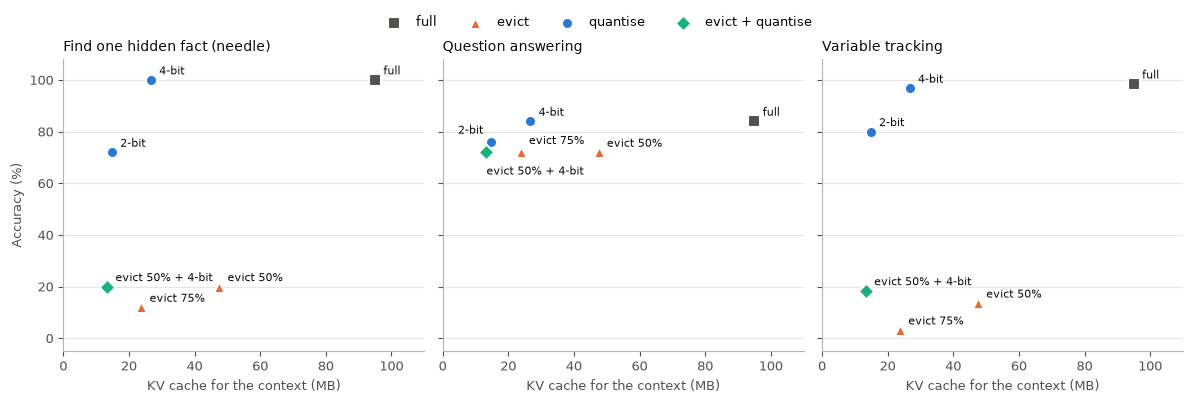

In [4]:
FAMILY = {"full_fp16": "full", "kv_int4": "quantise", "kv_int2": "quantise",
          "h2o_50": "evict", "h2o_75": "evict", "h2o_50+kv_int4": "evict + quantise"}
COLOR = {"full": "#52514e", "quantise": "#2a78d6", "evict": "#eb6834", "evict + quantise": "#1baf7a"}
MARKER = {"full": "s", "quantise": "o", "evict": "^", "evict + quantise": "D"}
LABEL = {"full_fp16": "full", "kv_int4": "4-bit", "kv_int2": "2-bit",
         "h2o_50": "evict 50%", "h2o_75": "evict 75%", "h2o_50+kv_int4": "evict 50% + 4-bit"}
TITLE = {"niah_single_1": "Find one hidden fact (needle)", "qa_1": "Question answering", "vt": "Variable tracking"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

# label offsets (points) where labels would otherwise collide
OFFSET = {("qa_1", "kv_int2"): (-6, 6, "right"),
          ("qa_1", "h2o_50+kv_int4"): (0, -16, "left"),
          ("qa_1", "h2o_75"): (6, 6, "left")}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, task in zip(axes, TASKS):
    for cond, row in summary.iterrows():
        fam = FAMILY[cond]
        ax.scatter(row["kv_ctx_mb"], row[task], s=64, color=COLOR[fam], marker=MARKER[fam],
                   edgecolor="white", linewidth=1.5, zorder=3, label=fam)
        dx, dy, ha = OFFSET.get((task, cond), (6, 4, "left"))
        ax.annotate(LABEL[cond], (row["kv_ctx_mb"], row[task]), xytext=(dx, dy), ha=ha,
                    textcoords="offset points", fontsize=8, color="#0b0b0b")
    ax.set_title(TITLE[task], loc="left", fontsize=10, color="#0b0b0b")
    ax.set_xlabel("KV cache for the context (MB)")
    ax.set_xlim(0, 110)
    ax.set_ylim(-5, 108)
    ax.grid(axis="y", color="#e8e7e2", linewidth=0.8)
axes[0].set_ylabel("Accuracy (%)")
h, l = axes[0].get_legend_handles_labels()
uniq = dict(zip(l, h))
fig.legend(uniq.values(), uniq.keys(), loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(f"{R}/accuracy_vs_kv.png", dpi=160, bbox_inches="tight")
plt.show()

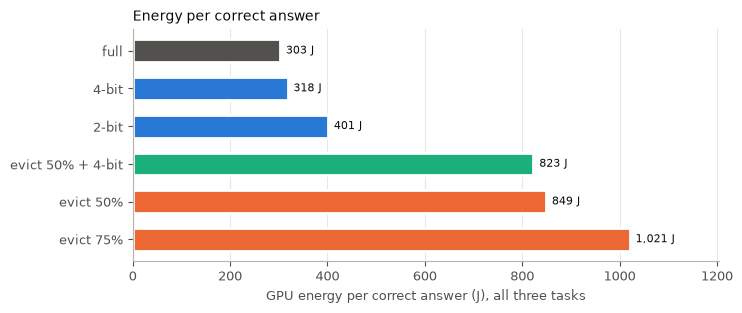

In [5]:
s = summary.sort_values("j_per_correct")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = range(len(s))
ax.barh(list(y), s["j_per_correct"], height=0.6, color=[COLOR[FAMILY[c]] for c in s.index], edgecolor="white", linewidth=2)
ax.set_yticks(list(y), [LABEL[c] for c in s.index])
ax.invert_yaxis()
for i, v in enumerate(s["j_per_correct"]):
    ax.text(v + 12, i, f"{v:,.0f} J", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("GPU energy per correct answer (J), all three tasks")
ax.set_title("Energy per correct answer", loc="left", fontsize=10, color="#0b0b0b")
ax.set_xlim(0, s["j_per_correct"].max() * 1.18)
ax.grid(axis="x", color="#e8e7e2", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{R}/energy_per_correct.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Energy per correct answer, by task

Where a condition answers almost nothing correctly, its energy per correct answer explodes (eviction on variable tracking).

In [6]:
jpc_task.round(0).astype(int)

,niah_single_1,qa_1,vt
condition,,,
full_fp16,296,247,357
h2o_50,1570,285,2775
h2o_75,2589,288,11641
kv_int4,324,251,370
kv_int2,449,286,468
h2o_50+kv_int4,1586,290,2079


## 5. Per-answer uncertainty (optional)

With 25 questions per task, a single score can move by about 20 points by chance. If `results/results.csv` (one row per answer) is present, this cell adds bootstrap 95% intervals to each task score.

In [7]:
path = f"{R}/results.csv"
if os.path.exists(path):
    import numpy as np
    df = pd.read_csv(path)
    rng = np.random.default_rng(0)
    out = []
    for (cond, task), g in df.groupby(["condition", "task"]):
        x = g["score"].to_numpy()
        boots = rng.choice(x, size=(5000, len(x)), replace=True).mean(axis=1)
        out.append({"condition": cond, "task": task, "score": x.mean().round(1),
                    "95% CI": f"{np.percentile(boots, 2.5):.0f}-{np.percentile(boots, 97.5):.0f}"})
    display(pd.DataFrame(out).pivot(index="condition", columns="task", values=["score", "95% CI"]))
else:
    print("results/results.csv not found: add it from the Kaggle output to see confidence intervals.")

results/results.csv not found: add it from the Kaggle output to see confidence intervals.


## Findings

1. **4-bit KIVI-style quantisation is nearly lossless.** It cut the cache to 28% of its size (3.6x smaller) with mean accuracy 93.6 against 94.1 for the full cache.
2. **At equal memory, quantising beats evicting by a wide margin.** At about 25 MB, the 4-bit cache found the hidden fact in 100% of cases against 12% for 75% eviction, and scored 96.8 against 3.2 on variable tracking.
3. **The cost of compression depends on the task.** Eviction cost little on general question answering (72 against 84) but erased exact recall. Eviction here scores tokens before the question is seen, so it cannot know which facts the question will need.
4. **Memory saved was not energy saved at this length.** Every compressed condition used 4-7% more energy per answer than the full cache and ran 5-8% slower: at 4k tokens with one request at a time the cache is small next to the weights, and the compression adds work.
5. **Energy per correct answer separates the methods.** At equal memory, 4-bit quantisation needed 69% less energy per correct answer than 75% eviction (318 J against 1,021 J), and 2-bit needed 51% less than eviction plus 4-bit (401 J against 823 J). The saving comes from answers staying correct, not from cheaper queries.